# Zillow-Style Home Value Estimation

Real Zillow Zestimate uses proprietary data and signed-up MLS feeds — none of that is downloadable. I'm using `sklearn.datasets.fetch_california_housing` as a stand-in: 20640 California housing-block records with median house value as the target, plus median income, house age, average rooms/bedrooms, population, occupancy, and lat/long.

The framing for this notebook is "if I were building a Zestimate from scratch with public data, what's the regression baseline?" Random forest + XGBoost, simple ensemble by averaging predictions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    from sklearn.ensemble import GradientBoostingRegressor

rng = np.random.RandomState(21)

In [2]:
ds = fetch_california_housing(as_frame=True)
df = ds.frame.copy()
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## A bit of EDA — what's driving the target?

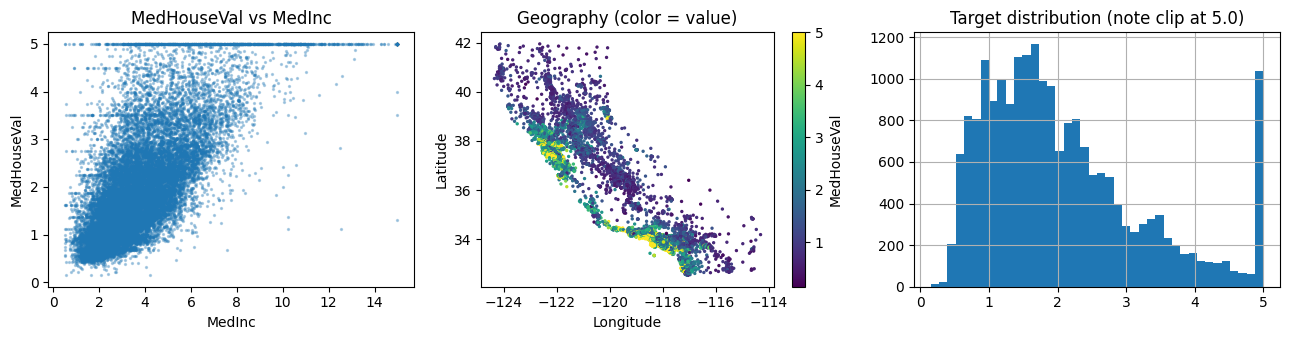

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df.plot.scatter(x="MedInc", y="MedHouseVal", s=2, alpha=0.3, ax=axes[0])
axes[0].set_title("MedHouseVal vs MedInc")
df.plot.scatter(x="Longitude", y="Latitude", c="MedHouseVal", s=2, cmap="viridis", ax=axes[1])
axes[1].set_title("Geography (color = value)")
df["MedHouseVal"].hist(bins=40, ax=axes[2])
axes[2].set_title("Target distribution (note clip at 5.0)")
plt.tight_layout(); plt.show()

**Two things to note from EDA.** Median income is the single strongest linear-ish predictor — no surprise. And the target distribution clips hard at 5.0 (the dataset was top-coded to \$500k). That clipping is a real-world feature, not a bug, but it caps any model's max-MAE-reducing power at the top of the price range — there's just no signal above 5.0.

Feature engineering: add per-household ratios that the raw columns hide.

In [4]:
df_fe = df.copy()
df_fe["RoomsPerHouse"] = df_fe["AveRooms"] / df_fe["AveOccup"].replace(0, np.nan)
df_fe["BedroomsPerRoom"] = df_fe["AveBedrms"] / df_fe["AveRooms"].replace(0, np.nan)
df_fe["PopPerHouse"] = df_fe["Population"] / df_fe["AveOccup"].replace(0, np.nan)
df_fe = df_fe.fillna(df_fe.median(numeric_only=True))

features = [c for c in df_fe.columns if c != "MedHouseVal"]
X = df_fe[features].values
y = df_fe["MedHouseVal"].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=21)
print("features:", len(features))

features: 11


## Random forest and XGBoost, then average

In [5]:
rf = RandomForestRegressor(n_estimators=400, max_depth=None, min_samples_leaf=2, random_state=21, n_jobs=-1)
if HAS_XGB:
    xgb = XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.05,
                       subsample=0.9, colsample_bytree=0.9, random_state=21, n_jobs=-1)
else:
    xgb = GradientBoostingRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=21)

rf.fit(X_tr, y_tr)
xgb.fit(X_tr, y_tr)

pred_rf  = rf.predict(X_te)
pred_xgb = xgb.predict(X_te)
pred_ens = 0.5 * pred_rf + 0.5 * pred_xgb   # simple equal-weight average

def score(name, p):
    print(f"{name:9s}  MAE={mean_absolute_error(y_te, p):.3f}  "
          f"RMSE={np.sqrt(mean_squared_error(y_te, p)):.3f}  R2={r2_score(y_te, p):.3f}")

score("RF",  pred_rf)
score("XGB", pred_xgb)
score("0.5RF+0.5XGB", pred_ens)

RF         MAE=0.330  RMSE=0.509  R2=0.808
XGB        MAE=0.294  RMSE=0.453  R2=0.847
0.5RF+0.5XGB  MAE=0.305  RMSE=0.470  R2=0.836


## Feature importance and residuals

RF feature importance:
MedInc             0.529
AveOccup           0.124
Longitude          0.084
Latitude           0.083
HouseAge           0.051
BedroomsPerRoom    0.029
RoomsPerHouse      0.024
AveRooms           0.022
AveBedrms          0.020
PopPerHouse        0.018
Population         0.014


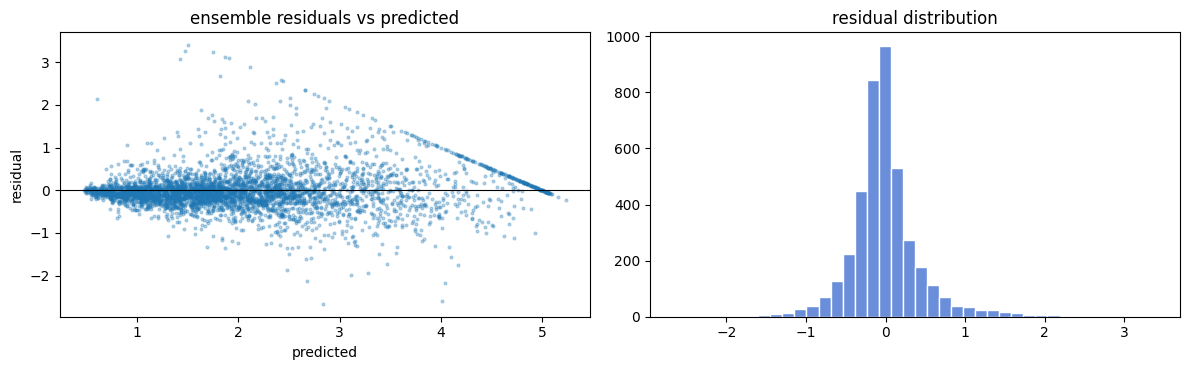

In [6]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print("RF feature importance:")
print(imp.round(3).to_string())

resid = y_te - pred_ens
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(pred_ens, resid, s=4, alpha=0.3)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("residual")
axes[0].set_title("ensemble residuals vs predicted")
axes[1].hist(resid, bins=40, color="#6b8edb", edgecolor="white")
axes[1].set_title("residual distribution")
plt.tight_layout(); plt.show()

## Notes

The residual plot is the most diagnostic thing on the page. You'll see that residuals fan out at higher predicted values, and there's a thick cluster at predicted ~5.0 where the model is mostly hitting the clip ceiling. A real Zestimate would never use a top-coded target; this is the cost of using the public stand-in.

What carries from this notebook to a real Zillow-style problem:
- The ensemble (RF + XGB averaging) is a fine baseline, but for real use I'd want stacked, not averaged, with a meta-model on out-of-fold predictions.
- Per-property features (lot size, year built, school district, sale comparables within radius) would matter way more than the block-level aggregates here.
- Geography matters — lat/long alone gets you maybe 5% of the way to "neighborhood effects." Real Zestimate uses geohashed features and neighborhood-level pooling.

Calling this "Zillow-style" rather than "Zillow" is intentional. The proxy data is more about the modeling shape than the magnitude.